<a href="https://colab.research.google.com/github/HittersLab/Case-Exercises-Subsea-Integrity-Predictive-Analytics/blob/main/Case1_Design_Envelope/Case1_Design_Envelope.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Exercise 1: Design Envelope Construction and Visualisation

**Programme:** Predictive AI and Machine Learning  
**Domain:** Subsea Asset Integrity  
**Case Study:** Usan Field Subsea Jumpers  
**Prepared by:** Ndolo Nekabari  
**Date:** 19, October, 2026

---

## Project Overview

This project demonstrates how Python can be applied to subsea asset integrity monitoring through the construction and visualisation of a pressure temperature design envelope. It combines engineering operating limits, jumper inspection data, synthetic flow rate data, and synthetic hourly operating records to assess operating conditions against defined constraints.

The work covers four main tasks: implementing a pressure temperature envelope function, visualising operating points, extending the analysis to pressure, temperature, and flow rate, and calculating the percentage of operating records within selected design limits.

**Scope:** This is an educational engineering analysis. Synthetic values are clearly identified and must not be treated as verified field measurements or approved operating limits.

**Imports and Configuration of Python Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create a folder for the datasets
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# Engineering values from the training exercise
MAOP_PSI = 4467.0
P_MIN_PSI = 500.0
T_MIN_SEABED_C = 4.0
T_MAX_RESERVOIR_C = 82.0
HYDRATE_OFFSET_C = 5.0

# Synthetic assumption for demonstration only
WAT_C = 35.0

print("Libraries imported successfully.")
print(f"MAOP: {MAOP_PSI:.0f} psi")
print(f"Synthetic WAT assumption: {WAT_C:.1f} °C")

Libraries imported successfully.
MAOP: 4467 psi
Synthetic WAT assumption: 35.0 °C


## Supplied Jumper Inspection Data

The exercise provides six jumper records containing outer diameter, original and current wall thickness, corrosion rate, pressure, temperature, and water cut.

These records will be used to evaluate the supplied operating points against the simplified pressure–temperature envelope. Flow rates and hourly operating history were not supplied and will be generated separately as clearly labelled synthetic data.

In [2]:
jumper_data = pd.DataFrame([
    {
        "jumper_id": "J-001",
        "outer_diameter_in": 10.75,
        "original_wall_thickness_mm": 12.7,
        "current_wall_thickness_mm": 11.2,
        "corrosion_rate_mm_per_year": 0.15,
        "pressure_psi": 4200,
        "temperature_c": 65,
        "water_cut_pct": 32
    },
    {
        "jumper_id": "J-002",
        "outer_diameter_in": 10.75,
        "original_wall_thickness_mm": 12.7,
        "current_wall_thickness_mm": 10.8,
        "corrosion_rate_mm_per_year": 0.19,
        "pressure_psi": 4400,
        "temperature_c": 72,
        "water_cut_pct": 45
    },
    {
        "jumper_id": "J-003",
        "outer_diameter_in": 10.75,
        "original_wall_thickness_mm": 12.7,
        "current_wall_thickness_mm": 11.5,
        "corrosion_rate_mm_per_year": 0.12,
        "pressure_psi": 3800,
        "temperature_c": 58,
        "water_cut_pct": 28
    },
    {
        "jumper_id": "J-004",
        "outer_diameter_in": 8.625,
        "original_wall_thickness_mm": 10.3,
        "current_wall_thickness_mm": 8.9,
        "corrosion_rate_mm_per_year": 0.14,
        "pressure_psi": 3200,
        "temperature_c": 55,
        "water_cut_pct": 38
    },
    {
        "jumper_id": "J-005",
        "outer_diameter_in": 10.75,
        "original_wall_thickness_mm": 12.7,
        "current_wall_thickness_mm": 10.1,
        "corrosion_rate_mm_per_year": 0.26,
        "pressure_psi": 4467,
        "temperature_c": 78,
        "water_cut_pct": 62
    },
    {
        "jumper_id": "J-006",
        "outer_diameter_in": 10.75,
        "original_wall_thickness_mm": 12.7,
        "current_wall_thickness_mm": 11.0,
        "corrosion_rate_mm_per_year": 0.17,
        "pressure_psi": 4100,
        "temperature_c": 68,
        "water_cut_pct": 40
    }
])

jumper_data["data_status"] = "SOURCE-PROVIDED EXERCISE DATA"

jumper_data

,jumper_id,outer_diameter_in,original_wall_thickness_mm,current_wall_thickness_mm,corrosion_rate_mm_per_year,pressure_psi,temperature_c,water_cut_pct,data_status
0,J-001,10.750,12.7,11.2,0.15,4200,65,32,SOURCE-PROVIDED EXERCISE DATA
1,J-002,10.750,12.7,10.8,0.19,4400,72,45,SOURCE-PROVIDED EXERCISE DATA
2,J-003,10.750,12.7,11.5,0.12,3800,58,28,SOURCE-PROVIDED EXERCISE DATA
3,J-004,8.625,10.3,8.9,0.14,3200,55,38,SOURCE-PROVIDED EXERCISE DATA
4,J-005,10.750,12.7,10.1,0.26,4467,78,62,SOURCE-PROVIDED EXERCISE DATA
5,J-006,10.750,12.7,11.0,0.17,4100,68,40,SOURCE-PROVIDED EXERCISE DATA


## Question 1: Implement `pressure_temperature_envelope()`

### Answer

A design envelope defines the range of operating conditions within which an asset is intended to operate under specified engineering constraints.

For this exercise, the function generates a series of pressure values between the selected minimum and maximum pressures. It then calculates a simplified hydrate formation temperature using the equation provided in the training material:

\[
T_{\text{hydrate}} = 4 + 18\log_{10}\left(\frac{P}{200}\right)
\]

An illustrative 5°C offset is added to the hydrate curve to demonstrate a temperature margin. The function includes input validation, error handling, documentation, and a dictionary containing the calculated results and limits.

In [3]:
def pressure_temperature_envelope(
    p_max=MAOP_PSI,
    p_min=P_MIN_PSI,
    t_min_seabed=T_MIN_SEABED_C,
    t_max_reservoir=T_MAX_RESERVOIR_C,
    hydrate_offset=HYDRATE_OFFSET_C,
    n_points=100
):
    """
    Construct a simplified pressure-temperature envelope.

    Parameters
    ----------
    p_max : float
        Maximum pressure in psi.
    p_min : float
        Minimum pressure in psi.
    t_min_seabed : float
        Seabed temperature in degrees Celsius.
    t_max_reservoir : float
        Upper temperature boundary in degrees Celsius.
    hydrate_offset : float
        Illustrative temperature offset above the hydrate curve.
    n_points : int
        Number of pressure points to calculate.

    Returns
    -------
    dict
        Pressure values, hydrate temperatures, safe minimum
        temperatures, and the selected limits.
    """

    values = {
        "p_max": p_max,
        "p_min": p_min,
        "t_min_seabed": t_min_seabed,
        "t_max_reservoir": t_max_reservoir,
        "hydrate_offset": hydrate_offset
    }

    for name, value in values.items():
        if isinstance(value, bool) or not isinstance(
            value, (int, float, np.number)
        ):
            raise TypeError(f"{name} must be numeric.")

        if not np.isfinite(value):
            raise ValueError(f"{name} must be finite.")

    if p_min <= 0:
        raise ValueError("p_min must be greater than zero.")

    if p_max <= p_min:
        raise ValueError("p_max must be greater than p_min.")

    if t_max_reservoir <= t_min_seabed:
        raise ValueError(
            "Maximum temperature must exceed minimum temperature."
        )

    if hydrate_offset < 0:
        raise ValueError("hydrate_offset cannot be negative.")

    if isinstance(n_points, bool) or not isinstance(n_points, int):
        raise TypeError("n_points must be an integer.")

    if n_points < 2:
        raise ValueError("n_points must be at least 2.")

    # Generate pressure values
    pressures = np.linspace(p_min, p_max, n_points)

    # Simplified hydrate equation supplied in the training material
    hydrate_temperature = (
        t_min_seabed
        + 18.0 * np.log10(pressures / 200.0)
    )

    # Add illustrative temperature offset
    safe_min_temperature = hydrate_temperature + hydrate_offset

    return {
        "pressures": pressures,
        "hydrate_temperature_c": hydrate_temperature,
        "safe_min_temperature_c": safe_min_temperature,
        "p_min_psi": float(p_min),
        "p_max_psi": float(p_max),
        "t_min_seabed_c": float(t_min_seabed),
        "t_max_reservoir_c": float(t_max_reservoir),
        "hydrate_offset_c": float(hydrate_offset)
    }


# Generate the envelope
envelope = pressure_temperature_envelope()

print("Envelope generated successfully.")
print("Number of pressure points:", len(envelope["pressures"]))
print("Minimum pressure:", envelope["p_min_psi"], "psi")
print("Maximum pressure:", envelope["p_max_psi"], "psi")

Envelope generated successfully.
Number of pressure points: 100
Minimum pressure: 500.0 psi
Maximum pressure: 4467.0 psi


**Question 1 validation tests**

In [4]:
# Test the output size and pressure boundaries
assert len(envelope["pressures"]) == 100
assert np.isclose(envelope["pressures"][0], P_MIN_PSI)
assert np.isclose(envelope["pressures"][-1], MAOP_PSI)

# Test invalid minimum pressure
try:
    pressure_temperature_envelope(p_min=0)
except ValueError:
    print("Test passed: zero pressure was rejected.")
else:
    raise AssertionError("Zero pressure should be rejected.")

# Test invalid pressure range
try:
    pressure_temperature_envelope(p_max=100)
except ValueError:
    print("Test passed: invalid pressure range was rejected.")
else:
    raise AssertionError("Invalid pressure range should be rejected.")

# Test invalid number of points
try:
    pressure_temperature_envelope(n_points=1)
except ValueError:
    print("Test passed: invalid number of points was rejected.")
else:
    raise AssertionError("n_points=1 should be rejected.")

print("All Question 1 tests passed.")

Test passed: zero pressure was rejected.
Test passed: invalid pressure range was rejected.
Test passed: invalid number of points was rejected.
All Question 1 tests passed.


## Question 2: Plot the 2D Pressure–Temperature Envelope

### Answer

The pressure temperature plot visualises the simplified hydrate formation curve, the hydrate curve plus an illustrative 5°C offset, the synthetic WAT boundary, the MAOP boundary, and the six jumper operating points.

The lower temperature boundary is taken as the higher of the synthetic WAT and the offset hydrate curve. The upper temperature boundary is 82°C, as given in the training material.

The WAT value of 35°C is a synthetic assumption for this exercise. It must not be interpreted as a verified field measurement.

**Python solution: for creating the plot**


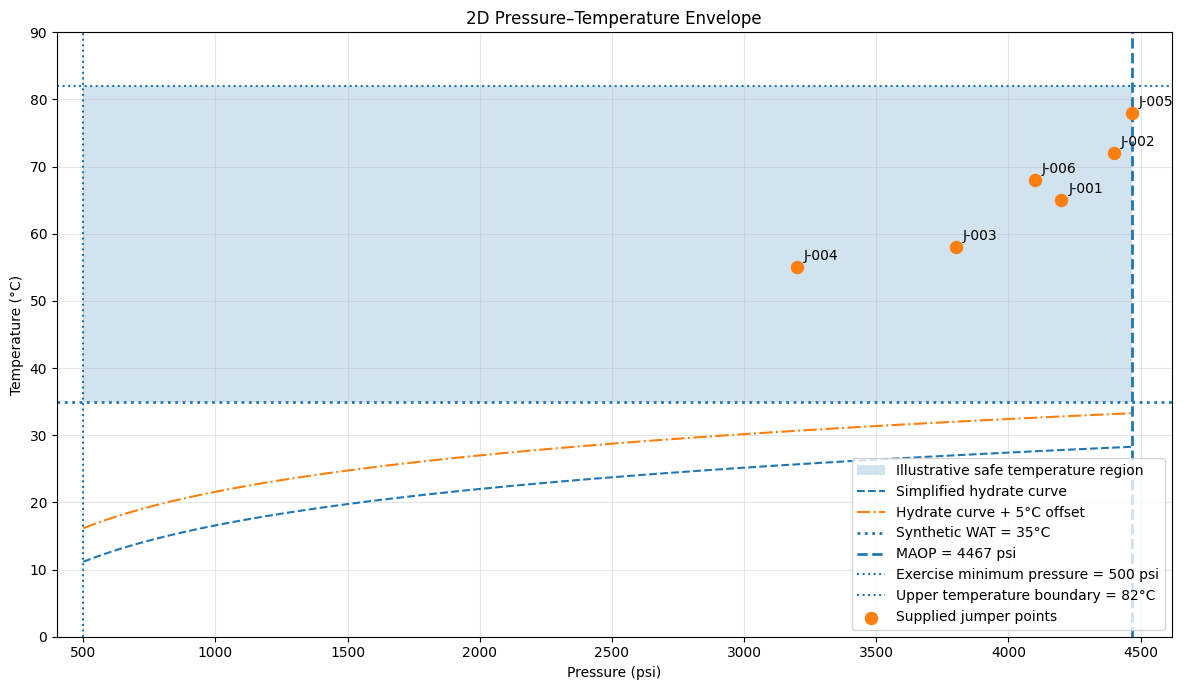

In [5]:
# Retrieve calculated envelope arrays
pressures = envelope["pressures"]
hydrate_temperature = envelope["hydrate_temperature_c"]
safe_hydrate_temperature = envelope["safe_min_temperature_c"]

# Apply the illustrative WAT boundary
lower_temperature_boundary = np.maximum(
    safe_hydrate_temperature,
    WAT_C
)

plt.figure(figsize=(12, 7))

# Shade the illustrative operating region
plt.fill_between(
    pressures,
    lower_temperature_boundary,
    envelope["t_max_reservoir_c"],
    where=(
        lower_temperature_boundary
        <= envelope["t_max_reservoir_c"]
    ),
    alpha=0.2,
    label="Illustrative safe temperature region"
)

# Plot the hydrate curve and temperature margin
plt.plot(
    pressures,
    hydrate_temperature,
    linestyle="--",
    label="Simplified hydrate curve"
)

plt.plot(
    pressures,
    safe_hydrate_temperature,
    linestyle="-.",
    label="Hydrate curve + 5°C offset"
)

# Plot the synthetic WAT and pressure/temperature boundaries
plt.axhline(
    WAT_C,
    linestyle=":",
    linewidth=2,
    label=f"Synthetic WAT = {WAT_C:.0f}°C"
)

plt.axvline(
    MAOP_PSI,
    linestyle="--",
    linewidth=2,
    label=f"MAOP = {MAOP_PSI:.0f} psi"
)

plt.axvline(
    P_MIN_PSI,
    linestyle=":",
    label=f"Exercise minimum pressure = {P_MIN_PSI:.0f} psi"
)

plt.axhline(
    T_MAX_RESERVOIR_C,
    linestyle=":",
    label="Upper temperature boundary = 82°C"
)

# Plot the six supplied jumper points
plt.scatter(
    jumper_data["pressure_psi"],
    jumper_data["temperature_c"],
    s=75,
    zorder=5,
    label="Supplied jumper points"
)

# Label each jumper
for _, row in jumper_data.iterrows():
    plt.annotate(
        row["jumper_id"],
        (row["pressure_psi"], row["temperature_c"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Pressure (psi)")
plt.ylabel("Temperature (°C)")
plt.title("2D Pressure–Temperature Envelope")
plt.xlim(P_MIN_PSI - 100, MAOP_PSI + 150)
plt.ylim(0, 90)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Classifying the six jumper points**

In [6]:
def classify_pt_points(data, envelope, wat_c):
    """
    Classify jumper points against the simplified
    pressure-temperature envelope.
    """

    required = {
        "jumper_id",
        "pressure_psi",
        "temperature_c"
    }

    missing = required - set(data.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if not isinstance(wat_c, (int, float, np.number)):
        raise TypeError("wat_c must be numeric.")

    if not np.isfinite(wat_c):
        raise ValueError("wat_c must be finite.")

    result = data.copy()

    result["pressure_psi"] = pd.to_numeric(
        result["pressure_psi"], errors="coerce"
    )

    result["temperature_c"] = pd.to_numeric(
        result["temperature_c"], errors="coerce"
    )

    valid = (
        np.isfinite(result["pressure_psi"])
        & np.isfinite(result["temperature_c"])
    )

    positive_pressure = result["pressure_psi"] > 0

    result["pressure_within_limits"] = (
        valid
        & result["pressure_psi"].between(
            envelope["p_min_psi"],
            envelope["p_max_psi"]
        )
    )

    hydrate_temperature = (
        envelope["t_min_seabed_c"]
        + 18.0 * np.log10(
            result["pressure_psi"].where(
                positive_pressure, np.nan
            ) / 200.0
        )
    )

    result["hydrate_plus_offset_c"] = (
        hydrate_temperature + envelope["hydrate_offset_c"]
    )

    result["temperature_above_hydrate_limit"] = (
        valid
        & positive_pressure
        & (
            result["temperature_c"]
            >= result["hydrate_plus_offset_c"]
        )
    )

    result["temperature_above_wat"] = (
        valid & (result["temperature_c"] >= wat_c)
    )

    result["temperature_below_upper_limit"] = (
        valid
        & (
            result["temperature_c"]
            <= envelope["t_max_reservoir_c"]
        )
    )

    result["within_pt_envelope"] = (
        result["pressure_within_limits"]
        & result["temperature_above_hydrate_limit"]
        & result["temperature_above_wat"]
        & result["temperature_below_upper_limit"]
    )

    return result


jumper_classification = classify_pt_points(
    jumper_data,
    envelope,
    WAT_C
)

jumper_classification[[
    "jumper_id",
    "pressure_psi",
    "temperature_c",
    "pressure_within_limits",
    "temperature_above_hydrate_limit",
    "temperature_above_wat",
    "temperature_below_upper_limit",
    "within_pt_envelope"
]]

,jumper_id,pressure_psi,temperature_c,pressure_within_limits,temperature_above_hydrate_limit,temperature_above_wat,temperature_below_upper_limit,within_pt_envelope
0,J-001,4200,65,True,True,True,True,True
1,J-002,4400,72,True,True,True,True,True
2,J-003,3800,58,True,True,True,True,True
3,J-004,3200,55,True,True,True,True,True
4,J-005,4467,78,True,True,True,True,True
5,J-006,4100,68,True,True,True,True,True


## Synthetic Dataset Construction for Question 3 and 4

The supplied jumper inspection table does not include measured flow rates or a time-stamped operating history. To complete Questions 3 and 4, synthetic data are created for demonstration.

1. **Synthetic jumper flow rate data:** illustrative flow rates are assigned to the six supplied jumper records.
2. **Synthetic hourly operating history:** 720 hourly records are generated to represent 30 days of example operating data.
3. **Deliberate excursions:** selected records are assigned values outside one or more limits to test the classification and compliance calculations.

All synthetic data are labelled in the dataset. They must not be represented as measured field data.

Generating of  the synthetic datasets using pytrhon code

In [7]:
# Ensure the data folder exists
DATA_DIR.mkdir(exist_ok=True)

# Save the six supplied jumper records
jumper_data.to_csv(
    DATA_DIR / "jumper_inspection_data_source_provided.csv",
    index=False
)

# -------------------------------------------------
# Dataset 1: Synthetic flow rates for Question 3
# -------------------------------------------------

synthetic_flow_data = jumper_data[
    [
        "jumper_id",
        "pressure_psi",
        "temperature_c",
        "water_cut_pct"
    ]
].copy()

# Illustrative synthetic flow rates in barrels per day
synthetic_flow_data["flow_rate_bpd"] = [
    12000, 15000, 10000, 9000, 18000, 13500
]

synthetic_flow_data["data_status"] = (
    "SYNTHETIC FLOW RATE; OTHER VALUES FROM EXERCISE TABLE"
)

synthetic_flow_data.to_csv(
    DATA_DIR / "synthetic_jumper_flow_rates_demo.csv",
    index=False
)

# -------------------------------------------------
# Dataset 2: Synthetic hourly history for Question 4
# -------------------------------------------------

rng = np.random.default_rng(20261019)

n_hours = 720

synthetic_hourly_data = pd.DataFrame({
    "timestamp": pd.date_range(
        start="2026-09-01 00:00:00",
        periods=n_hours,
        freq="h"
    ),
    "pressure_psi": np.clip(
        rng.normal(4100, 220, n_hours), 300, 4800
    ),
    "temperature_c": np.clip(
        rng.normal(66, 7, n_hours), -5, 100
    ),
    "flow_rate_bpd": np.clip(
        rng.normal(14000, 2500, n_hours), 0, 40000
    ),
    "water_cut_pct": np.clip(
        rng.normal(40, 10, n_hours), 0, 100
    )
})

# Insert deliberate test excursions
synthetic_hourly_data.loc[
    [55, 190, 421], "pressure_psi"
] = [4700, 4800, 490]

synthetic_hourly_data.loc[
    [80, 250, 510], "temperature_c"
] = [2, 95, 10]

synthetic_hourly_data.loc[
    [100, 360, 600], "flow_rate_bpd"
] = [37000, 38000, 500]

synthetic_hourly_data.loc[
    [150, 450], "water_cut_pct"
] = [90, 95]

synthetic_hourly_data["data_status"] = (
    "SYNTHETIC DEMONSTRATION DATA - NOT FIELD HISTORY"
)

synthetic_hourly_data.to_csv(
    DATA_DIR / "synthetic_hourly_operating_history_demo.csv",
    index=False
)

print("Synthetic datasets created successfully.")

print("\nFlow-rate dataset:")
display(synthetic_flow_data.head())

print("\nHourly dataset:")
display(synthetic_hourly_data.head())

print("\nCSV files saved in:", DATA_DIR.resolve())

Synthetic datasets created successfully.

Flow-rate dataset:


,jumper_id,pressure_psi,temperature_c,water_cut_pct,flow_rate_bpd,data_status
0,J-001,4200,65,32,12000,SYNTHETIC FLOW RATE; OTHER VALUES FROM EXERCIS...
1,J-002,4400,72,45,15000,SYNTHETIC FLOW RATE; OTHER VALUES FROM EXERCIS...
2,J-003,3800,58,28,10000,SYNTHETIC FLOW RATE; OTHER VALUES FROM EXERCIS...
3,J-004,3200,55,38,9000,SYNTHETIC FLOW RATE; OTHER VALUES FROM EXERCIS...
4,J-005,4467,78,62,18000,SYNTHETIC FLOW RATE; OTHER VALUES FROM EXERCIS...



Hourly dataset:


,timestamp,pressure_psi,temperature_c,flow_rate_bpd,water_cut_pct,data_status
0,2026-09-01 00:00:00,4113.728956,77.406298,16475.328357,47.410809,SYNTHETIC DEMONSTRATION DATA - NOT FIELD HISTORY
1,2026-09-01 01:00:00,3862.454772,69.795502,17712.996487,24.834396,SYNTHETIC DEMONSTRATION DATA - NOT FIELD HISTORY
2,2026-09-01 02:00:00,4191.563748,55.672828,10306.518710,50.696485,SYNTHETIC DEMONSTRATION DATA - NOT FIELD HISTORY
3,2026-09-01 03:00:00,4243.784533,74.173703,12381.329139,22.328291,SYNTHETIC DEMONSTRATION DATA - NOT FIELD HISTORY
4,2026-09-01 04:00:00,3998.178267,68.296603,10734.807340,19.075322,SYNTHETIC DEMONSTRATION DATA - NOT FIELD HISTORY



CSV files saved in: /content/data


## Question 3: Develop a Three-Parameter Envelope

### Answer

A three-parameter envelope extends the pressure temperature assessment by including flow rate. For this exercise, the illustrative flow rate range is 0–35,000 barrels per day, based on the example limits provided in the training material.

Each jumper is classified using its pressure, temperature, and flow rate. The results are presented in a 3D scatter plot, with colour indicating whether the point falls within the illustrative combined envelope.

The flow-rate values are synthetic, so the plot demonstrates the analytical method rather than validated field performance.

In [8]:
def classify_pt_flow_points(
    data,
    envelope,
    wat_c,
    flow_min_bpd=0,
    flow_max_bpd=35000
):
    """
    Classify operating points against pressure,
    temperature, and flow-rate limits.
    """

    required = {
        "jumper_id",
        "pressure_psi",
        "temperature_c",
        "flow_rate_bpd"
    }

    missing = required - set(data.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if not (
        np.isfinite(flow_min_bpd)
        and np.isfinite(flow_max_bpd)
    ):
        raise ValueError("Flow limits must be finite.")

    if flow_min_bpd < 0 or flow_max_bpd <= flow_min_bpd:
        raise ValueError("Invalid flow-rate limits.")

    result = classify_pt_points(
        data,
        envelope,
        wat_c
    )

    result["flow_rate_bpd"] = pd.to_numeric(
        result["flow_rate_bpd"],
        errors="coerce"
    )

    result["flow_within_limits"] = (
        np.isfinite(result["flow_rate_bpd"])
        & result["flow_rate_bpd"].between(
            flow_min_bpd,
            flow_max_bpd
        )
    )

    result["within_pt_flow_envelope"] = (
        result["within_pt_envelope"]
        & result["flow_within_limits"]
    )

    result["envelope_status"] = np.where(
        result["within_pt_flow_envelope"],
        "Within illustrative envelope",
        "Outside illustrative envelope"
    )

    return result


flow_classification = classify_pt_flow_points(
    synthetic_flow_data,
    envelope,
    WAT_C,
    flow_min_bpd=0,
    flow_max_bpd=35000
)

flow_classification[[
    "jumper_id",
    "pressure_psi",
    "temperature_c",
    "flow_rate_bpd",
    "within_pt_envelope",
    "flow_within_limits",
    "envelope_status"
]]

,jumper_id,pressure_psi,temperature_c,flow_rate_bpd,within_pt_envelope,flow_within_limits,envelope_status
0,J-001,4200,65,12000,True,True,Within illustrative envelope
1,J-002,4400,72,15000,True,True,Within illustrative envelope
2,J-003,3800,58,10000,True,True,Within illustrative envelope
3,J-004,3200,55,9000,True,True,Within illustrative envelope
4,J-005,4467,78,18000,True,True,Within illustrative envelope
5,J-006,4100,68,13500,True,True,Within illustrative envelope


**Python solution: 3D scatter plot**

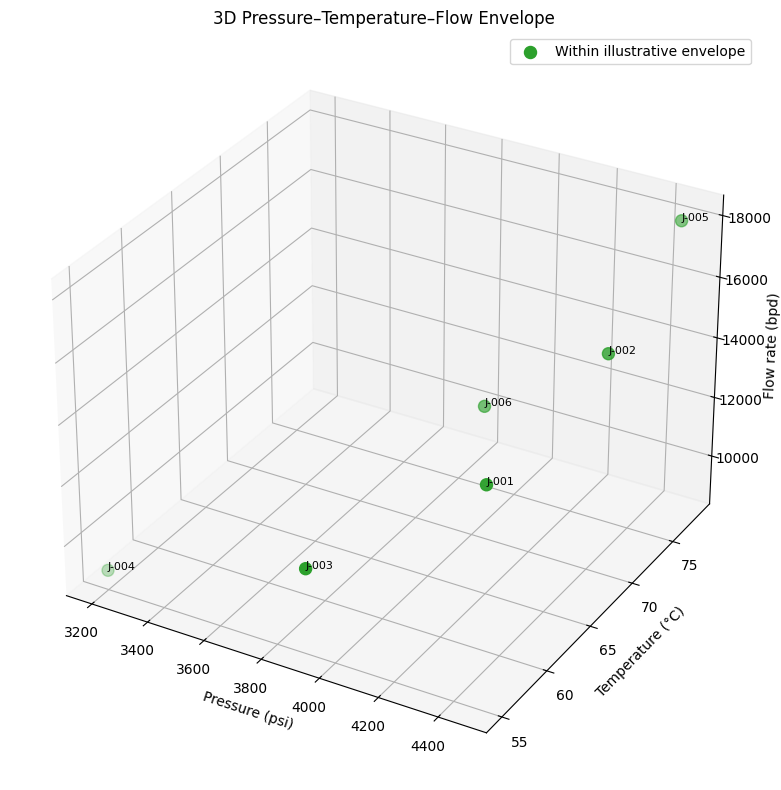

In [9]:
fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

status_colours = {
    "Within illustrative envelope": "tab:green",
    "Outside illustrative envelope": "tab:red"
}

for status, group in flow_classification.groupby(
    "envelope_status"
):
    ax.scatter(
        group["pressure_psi"],
        group["temperature_c"],
        group["flow_rate_bpd"],
        label=status,
        color=status_colours[status],
        s=75
    )

    for _, row in group.iterrows():
        ax.text(
            row["pressure_psi"],
            row["temperature_c"],
            row["flow_rate_bpd"],
            row["jumper_id"],
            fontsize=8
        )

ax.set_xlabel("Pressure (psi)")
ax.set_ylabel("Temperature (°C)")
ax.set_zlabel("Flow rate (bpd)")
ax.set_title("3D Pressure–Temperature–Flow Envelope")
ax.legend()

plt.tight_layout()
plt.show()

## Question 4: Calculate Percentage of Time Within the Design Envelope

### Answer

The percentage of time within a design limit can be estimated from regularly sampled operating records using:

\[
\text{Percentage within limit}
=
\frac{\text{Number of samples within limit}}
{\text{Total number of samples}}
\times 100
\]

The function calculates the percentage of records satisfying each individual parameter limit and the percentage satisfying all criteria together.

The assessment uses pressure limits of 500–4,467 psi, temperature limits incorporating the synthetic WAT and the offset hydrate curve, an upper temperature of 82°C, a flow-rate range of 0–35,000 bpd, and a water-cut range of 0–85%.

Because the dataset is synthetic and regularly sampled hourly, the results represent the percentage of generated hourly records within limits. Real operating data should be checked for missing records and irregular timestamps before interpreting sample percentages as actual time percentages.

In [10]:
def percentage_time_within_envelope(
    data,
    envelope,
    wat_c,
    flow_min_bpd=0,
    flow_max_bpd=35000,
    water_cut_min_pct=0,
    water_cut_max_pct=85
):
    """
    Calculate parameter-level and combined percentages
    of records within the exercise design envelope.

    Returns
    -------
    summary : pandas.DataFrame
        Counts and percentages within each criterion.
    combined_percentage : float
        Percentage satisfying all criteria.
    classified_data : pandas.DataFrame
        Input records plus classification columns.
    """

    required = {
        "pressure_psi",
        "temperature_c",
        "flow_rate_bpd",
        "water_cut_pct"
    }

    missing = required - set(data.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if data.empty:
        raise ValueError("The dataset must not be empty.")

    if not np.isfinite(wat_c):
        raise ValueError("WAT must be finite.")

    if flow_min_bpd < 0 or flow_max_bpd <= flow_min_bpd:
        raise ValueError("Invalid flow-rate limits.")

    if (
        water_cut_min_pct < 0
        or water_cut_max_pct <= water_cut_min_pct
        or water_cut_max_pct > 100
    ):
        raise ValueError("Invalid water-cut limits.")

    result = data.copy()

    numeric_columns = [
        "pressure_psi",
        "temperature_c",
        "flow_rate_bpd",
        "water_cut_pct"
    ]

    for column in numeric_columns:
        result[column] = pd.to_numeric(
            result[column],
            errors="coerce"
        )

    # Missing or non-numeric measurements are treated as invalid
    valid = pd.Series(True, index=result.index)

    for column in numeric_columns:
        valid &= np.isfinite(result[column])

    # Pressure check
    result["pressure_within_limits"] = (
        valid
        & result["pressure_psi"].between(
            envelope["p_min_psi"],
            envelope["p_max_psi"]
        )
    )

    # Temperature check
    positive_pressure = result["pressure_psi"] > 0

    hydrate_temperature = (
        envelope["t_min_seabed_c"]
        + 18.0 * np.log10(
            result["pressure_psi"].where(
                positive_pressure, np.nan
            ) / 200.0
        )
    )

    minimum_temperature = np.maximum(
        hydrate_temperature + envelope["hydrate_offset_c"],
        wat_c
    )

    result["temperature_within_limits"] = (
        valid
        & positive_pressure
        & (
            result["temperature_c"]
            >= minimum_temperature
        )
        & (
            result["temperature_c"]
            <= envelope["t_max_reservoir_c"]
        )
    )

    # Flow-rate check
    result["flow_within_limits"] = (
        valid
        & result["flow_rate_bpd"].between(
            flow_min_bpd,
            flow_max_bpd
        )
    )

    # Water-cut check
    result["water_cut_within_limits"] = (
        valid
        & result["water_cut_pct"].between(
            water_cut_min_pct,
            water_cut_max_pct
        )
    )

    check_columns = [
        "pressure_within_limits",
        "temperature_within_limits",
        "flow_within_limits",
        "water_cut_within_limits"
    ]

    # All criteria must pass for a record to be compliant
    result["within_all_limits"] = result[
        check_columns
    ].all(axis=1)

    # Calculate summary statistics
    total_records = len(result)
    summary_rows = []

    for column in check_columns:
        count = int(result[column].sum())

        summary_rows.append({
            "parameter": column.replace(
                "_within_limits", ""
            ).replace("_", " ").title(),
            "records_within_limit": count,
            "total_records": total_records,
            "percentage_within_limit": round(
                count / total_records * 100, 2
            )
        })

    combined_count = int(
        result["within_all_limits"].sum()
    )

    combined_percentage = (
        combined_count / total_records * 100
    )

    summary_rows.append({
        "parameter": "Combined envelope (all criteria)",
        "records_within_limit": combined_count,
        "total_records": total_records,
        "percentage_within_limit": round(
            combined_percentage, 2
        )
    })

    summary = pd.DataFrame(summary_rows)

    return summary, combined_percentage, result


# Apply the function to the synthetic hourly dataset
summary, combined_percentage, hourly_classification = (
    percentage_time_within_envelope(
        synthetic_hourly_data,
        envelope,
        WAT_C,
        flow_min_bpd=0,
        flow_max_bpd=35000,
        water_cut_min_pct=0,
        water_cut_max_pct=85
    )
)

print(
    "Combined percentage within all limits:",
    round(combined_percentage, 2),
    "%"
)

display(summary)

Combined percentage within all limits: 93.61 %


,parameter,records_within_limit,total_records,percentage_within_limit
0,Pressure,683,720,94.86
1,Temperature,715,720,99.31
2,Flow,718,720,99.72
3,Water Cut,718,720,99.72
4,Combined envelope (all criteria),674,720,93.61


**validation tests**

In [11]:
# Small example to test the function manually
test_data = pd.DataFrame({
    "pressure_psi": [1000, 2000, 5000, 3000],
    "temperature_c": [60, 60, 60, 60],
    "flow_rate_bpd": [10000, 10000, 10000, 40000],
    "water_cut_pct": [30, 30, 30, 30]
})

test_summary, test_combined_pct, test_classified = (
    percentage_time_within_envelope(
        test_data,
        envelope,
        WAT_C,
        flow_min_bpd=0,
        flow_max_bpd=35000
    )
)

pressure_pct = test_summary.loc[
    test_summary["parameter"] == "Pressure",
    "percentage_within_limit"
].iloc[0]

flow_pct = test_summary.loc[
    test_summary["parameter"] == "Flow",
    "percentage_within_limit"
].iloc[0]

assert pressure_pct == 75.0
assert flow_pct == 75.0
assert test_combined_pct == 50.0

print("Question 4 tests passed.")
display(test_summary)

Question 4 tests passed.


,parameter,records_within_limit,total_records,percentage_within_limit
0,Pressure,3,4,75.0
1,Temperature,4,4,100.0
2,Flow,3,4,75.0
3,Water Cut,4,4,100.0
4,Combined envelope (all criteria),2,4,50.0
